# Credit Scoring Using Digital Footprints: a reproduction

Research Seminar: Data Analysis in Finance, HSE University

**Paper:** Berg, T., Burg, V., Gombović, A. and Puri, M. (2020). On the rise of FinTechs: Credit scoring using digital footprints. *Review of Financial Studies*, 33(7), 2845–2897. We work from the July 2018 working paper version (FDIC CFR WP 2018-04).

**Group 7:** Arsentyev Arseniy, Grebennikova Polina, Kantemirova Elizaveta, Pushkarev Vladislav

The paper shows, on 254,808 purchases at a German online furniture shop, that ten simple variables a website records for free (device, operating system, email host, the hour of the purchase, typing errors) predict whether a customer pays the invoice as well as a credit bureau score does, and that the two together predict best. The shop's data is private. We first rebuild a sample from the paper's own tables and check that our code gives back the paper's numbers. Then we run the same tests on 307,511 public consumer loans of Home Credit, where the application form leaves a similar footprint.

## 1. Setup

Libraries, folders, colours and two settings: the random seed and the number of repetitions of the cross-validation in section 8 (the paper uses 100).

In [1]:
from pathlib import Path
import json
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.interpolate import interp1d
from scipy.optimize import brentq
from scipy.stats import chi2_contingency, norm, rankdata
from sklearn.metrics import roc_auc_score, roc_curve

ROOT = Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "figures"
DATA.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

SEED = 7
REPEATS = 100

NAVY, ORANGE, GREY, LIGHT = "#0F2C68", "#EB8C3C", "#A0A0A0", "#9DB2D9"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 80)

## 2. The paper's numbers

The paper reports, for every footprint variable, how many customers fall into each category and their default rate: Table 3 and Appendix Table A.3 for the 254,808 customers with a credit bureau score, Table 6 and Table A.4 for the 15,591 customers without one. It also reports the logit coefficients: Table 5, column 2 (footprint only) and column 3 (footprint and bureau score), and Table 7 for customers without a score. We type these numbers in. Default means that the unpaid invoice was sent to a debt collection agency, on average 3.5 months after the order.

Device and operating system enter the paper's regressions as combinations (Desktop/Windows, Mobile/Android and so on). Customers with the do-not-track setting have no device, system and channel; the paper gives them one dummy. A missing coefficient (`NaN`) means the paper does not report it: the 12 smaller email hosts, the "other" channel and the rare device combinations.

In [2]:
PAPER = pd.DataFrame([
    ("device", "Desktop/Windows", 123085, 0.74, 0, 0, 7688, 2.20, 0),
    ("device", "Desktop/Macintosh", 21158, 0.69, -0.07, -0.13, 1421, 1.69, -0.26),
    ("device", "Desktop/other", 1628, 0.74, np.nan, np.nan, 82, 6.10, np.nan),
    ("device", "Tablet/Android", 15111, 1.11, 0.29, 0.29, 857, 2.10, -0.22),
    ("device", "Tablet/iOS", 29940, 0.79, 0.08, 0.08, 1737, 1.44, -0.45),
    ("device", "Tablet/other", 524, 1.53, np.nan, np.nan, 24, 0.00, np.nan),
    ("device", "Mobile/Android", 13967, 2.53, 1.05, 0.95, 789, 7.73, 1.07),
    ("device", "Mobile/iOS", 11531, 1.80, 0.72, 0.57, 687, 4.66, 0.63),
    ("device", "Mobile/other", 1310, 1.15, np.nan, np.nan, 70, 4.43, np.nan),
    ("device", "Do not track", 36554, 0.88, -0.02, -0.07, 2236, 2.28, -0.16),
    ("email host", "Gmx", 58609, 0.82, 0, 0, 3681, 2.42, 0),
    ("email host", "Web", 54864, 0.86, -0.00, -0.02, 3352, 2.63, 0.02),
    ("email host", "T-Online", 30277, 0.51, -0.40, -0.35, 1711, 1.52, -0.39),
    ("email host", "Gmail", 27842, 1.25, 0.34, 0.28, 1694, 3.60, 0.32),
    ("email host", "Yahoo", 11922, 1.96, 0.75, 0.72, 732, 3.14, 0.17),
    ("email host", "Hotmail", 10241, 1.45, 0.35, 0.28, 546, 2.75, -0.02),
    ("email host", "Other", 61053, 0.90, np.nan, np.nan, 3875, 2.22, np.nan),
    ("channel", "Paid", 111398, 1.11, 0, 0, 6447, 2.89, 0),
    ("channel", "Direct", 45178, 0.84, -0.27, -0.28, 3262, 1.87, -0.42),
    ("channel", "Affiliate", 24769, 0.64, -0.49, -0.54, 1395, 2.65, -0.08),
    ("channel", "Organic", 18295, 0.86, -0.15, -0.15, 1178, 2.55, -0.05),
    ("channel", "Other", 18614, 0.69, np.nan, np.nan, 1073, 2.14, np.nan),
    ("channel", "Do not track", 36554, 0.88, 0, 0, 2236, 2.28, 0),
    ("check-out time", "Evening", 108543, 0.85, 0, 0, 6349, 2.05, 0),
    ("check-out time", "Night", 6913, 1.97, 0.80, 0.75, 369, 3.52, 0.45),
    ("check-out time", "Morning", 46600, 1.09, 0.28, 0.28, 2960, 2.74, 0.30),
    ("check-out time", "Afternoon", 92752, 0.89, 0.08, 0.08, 5913, 2.77, 0.39),
    ("name in email", "No", 71016, 1.24, 0, 0, 4433, 3.93, 0),
    ("name in email", "Yes", 183792, 0.82, -0.28, -0.29, 11158, 1.92, -0.59),
    ("number in email", "No", 213640, 0.84, 0, 0, 12967, 1.99, 0),
    ("number in email", "Yes", 41168, 1.41, 0.26, 0.23, 2624, 4.95, 0.63),
    ("lower case", "No", 235560, 0.84, 0, 0, 14566, 2.21, 0),
    ("lower case", "Yes", 19248, 2.14, 0.76, 0.74, 1025, 6.44, 0.95),
    ("email error", "No", 251308, 0.88, 0, 0, 15305, 2.31, 0),
    ("email error", "Yes", 3500, 5.09, 1.66, 1.67, 286, 12.24, 1.66),
], columns=["variable", "category", "n", "default %", "coef", "coef with score",
            "n unscorable", "default % unscorable", "coef unscorable"])

QUINTILES = pd.DataFrame({"n": [50966, 50964, 50956, 50983, 50939], "default %": [2.12, 1.01, 0.68, 0.47, 0.39]},
                         index=["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"])

PAPER_AUC = pd.DataFrame({"in sample": [0.683, 0.696, 0.736, 0.722], "out of sample": [0.680, 0.688, 0.728, 0.683]},
                         index=["bureau score", "footprint", "both", "footprint, unscorable"])
PAPER_DEFAULT, PAPER_DEFAULT_UNSCORABLE = 0.94, 2.49
VARIABLES = list(PAPER.variable.unique())
PAPER.head(12)

,variable,category,n,default %,coef,coef with score,n unscorable,default % unscorable,coef unscorable
0,device,Desktop/Windows,123085,0.74,0.00,0.00,7688,2.20,0.00
1,device,Desktop/Macintosh,21158,0.69,-0.07,-0.13,1421,1.69,-0.26
2,device,Desktop/other,1628,0.74,NaN,NaN,82,6.10,NaN
3,device,Tablet/Android,15111,1.11,0.29,0.29,857,2.10,-0.22
4,device,Tablet/iOS,29940,0.79,0.08,0.08,1737,1.44,-0.45
5,device,Tablet/other,524,1.53,NaN,NaN,24,0.00,NaN
6,device,Mobile/Android,13967,2.53,1.05,0.95,789,7.73,1.07
7,device,Mobile/iOS,11531,1.80,0.72,0.57,687,4.66,0.63
8,device,Mobile/other,1310,1.15,NaN,NaN,70,4.43,NaN
9,device,Do not track,36554,0.88,-0.02,-0.07,2236,2.28,-0.16


### Do the typed-in tables add up?

Every variable must cover all 254,808 (and 15,591) customers, and the default rates of its categories, weighted by their size, must give back the average default rate of the paper: 0.94% with a bureau score and 2.49% without.

In [3]:
def totals(n, rate):
    t = PAPER.groupby("variable", sort=False).apply(lambda g: pd.Series({
        "customers": g[n].sum(), "default %": (g[n] * g[rate]).sum() / g[n].sum()}), include_groups=False)
    return t.round(3)


pd.concat([totals("n", "default %"), totals("n unscorable", "default % unscorable")], axis=1,
          keys=["with bureau score", "without bureau score"])

with bureau score           without bureau score          
                        customers default %            customers default %
variable                                                                  
device                   254808.0     0.934              15591.0     2.490
email host               254808.0     0.937              15591.0     2.490
channel                  254808.0     0.935              15591.0     2.490
check-out time           254808.0     0.939              15591.0     2.489
name in email            254808.0     0.937              15591.0     2.492
number in email          254808.0     0.932              15591.0     2.488
lower case               254808.0     0.938              15591.0     2.488
email error              254808.0     0.938              15591.0     2.492

### How much does one variable say on its own?

The AUC (area under the ROC curve) is the probability that a randomly chosen customer who defaulted looks riskier than a randomly chosen customer who paid. 50% is a coin flip, 100% a perfect ranking. With only categories and their default rates, the AUC of a single variable can be computed exactly: rank the categories by default rate and count the pairs of a defaulter and a payer that end up in the right order (half a pair for a tie).

The paper does not report these single-variable AUCs, but it gives one number to check against: the AUC of the bureau score is 68.3%. The bureau score in five quintiles must come out a little lower, because inside a quintile all customers look the same.

In [4]:
def grouped_auc(n, rate):
    n, rate = np.asarray(n, float), np.asarray(rate, float)
    bad = n * rate / 100
    good = n - bad
    wins = sum(bad[i] * good[j] * ((rate[i] > rate[j]) + 0.5 * (rate[i] == rate[j]))
               for i in range(len(n)) for j in range(len(n)))
    return wins / bad.sum() / good.sum()


single = pd.DataFrame({
    "with bureau score": [grouped_auc(QUINTILES.n, QUINTILES["default %"])]
    + [grouped_auc(g.n, g["default %"]) for _, g in PAPER.groupby("variable", sort=False)],
    "without bureau score": [np.nan]
    + [grouped_auc(g["n unscorable"], g["default % unscorable"]) for _, g in PAPER.groupby("variable", sort=False)],
}, index=["bureau score, 5 quintiles"] + VARIABLES).round(3)
single

,with bureau score,without bureau score
"bureau score, 5 quintiles",0.673,NaN
device,0.591,0.604
email host,0.578,0.558
channel,0.549,0.546
check-out time,0.536,0.539
name in email,0.545,0.584
number in email,0.542,0.585
lower case,0.549,0.554
email error,0.531,0.537


The five quintiles of the bureau score give an AUC of 67.3%, one point below the paper's 68.3% for the score itself, as expected. Alone, every footprint variable is far weaker than the bureau score: the best one, the device, reaches 59.1%. But every one is better than a coin flip, and they are almost unrelated to each other, so together they can add up.

The chart puts the default rates of all categories next to the quintiles of the bureau score. It is the picture behind the paper's claim: simple variables spread customers over default rates as widely as the bureau score does.

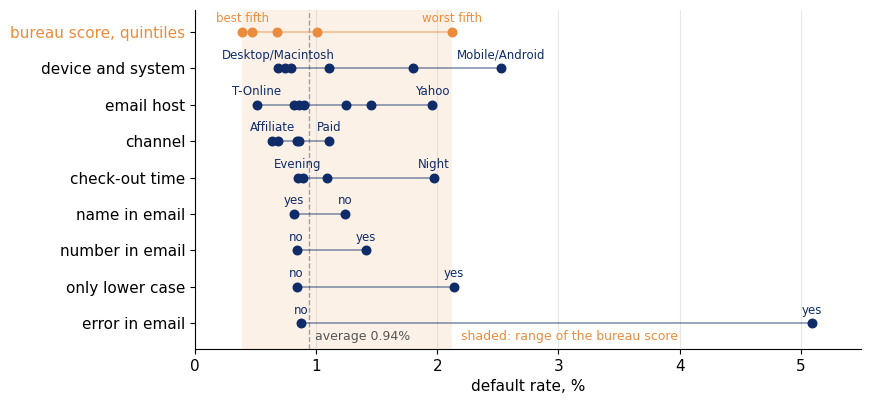

In [5]:
def spread_chart():
    rows = [("bureau score, quintiles", QUINTILES["default %"].values, ["worst fifth", "", "", "", "best fifth"])]
    names = {"device": "device and system", "email host": "email host", "channel": "channel",
             "check-out time": "check-out time", "name in email": "name in email", "number in email": "number in email",
             "lower case": "only lower case", "email error": "error in email"}
    for var, label in names.items():
        g = PAPER[(PAPER.variable == var) & (PAPER.category != "Do not track") & ~PAPER.category.str.endswith("/other")]
        rows.append((label, g["default %"].values, list(g.category)))
    fig, ax = plt.subplots(figsize=(8.6, 4.4))
    low, high = QUINTILES["default %"].min(), QUINTILES["default %"].max()
    ax.axvspan(low, high, color=ORANGE, alpha=0.12, lw=0)
    ax.axvline(PAPER_DEFAULT, color=GREY, lw=1, ls="--")
    ax.text(PAPER_DEFAULT + 0.05, 0.55, f"average {PAPER_DEFAULT}%", color="#555555", fontsize=9)
    for k, (label, rates, cats) in enumerate(rows):
        y = len(rows) - k
        color = ORANGE if k == 0 else NAVY
        ax.plot([rates.min(), rates.max()], [y, y], color=color, lw=1.2, alpha=0.5)
        ax.scatter(rates, [y] * len(rates), color=color, s=38, zorder=3)
        for r, c in [(rates.min(), cats[int(np.argmin(rates))]), (rates.max(), cats[int(np.argmax(rates))])]:
            ax.annotate(c.lower() if c in ("Yes", "No") else c, (r, y), textcoords="offset points", xytext=(0, 7),
                        ha="center", fontsize=8.5, color=color)
    ax.set_yticks(range(len(rows), 0, -1))
    ax.set_yticklabels([r[0] for r in rows])
    ax.get_yticklabels()[0].set_color(ORANGE)
    ax.set_xlim(0, 5.5)
    ax.set_xlabel("default rate, %")
    ax.grid(axis="y", alpha=0)
    ax.set_ylim(0.3, len(rows) + 0.6)
    ax.text(high + 0.08, 0.55, "shaded: range of the bureau score", color=ORANGE, fontsize=9)
    fig.savefig(FIG / "paper_spread.png")
    plt.show()


spread_chart()

## 3. A replica of the shop's customers

The customer-level data is private, but Tables 2, 3 and 5 describe it closely enough to rebuild a sample of the same size. We draw 254,808 customers:

- each footprint variable with the shares of Table 3 (device and operating system together, Table A.3); a customer with the do-not-track setting has no device, system and channel;
- the bureau score as a percentile from 0 (worst) to 100 (best); the log odds of default fall with the percentile, along a line through the five quintile default rates of Table 3;
- default from the logit of Table 5, column 3. Categories without a reported coefficient get the log odds ratio of their default rate against the baseline in Table 3. The constant is set so that the average default rate is 0.94%.

The variables are drawn independently of each other and of the bureau score. The paper's Table 4 shows that they are only weakly related (Cramér's V of 0.01 to 0.07 with the bureau score, below 0.25 between footprint variables except device and system), so this is a fair first approximation. If the paper's tables are consistent with each other, our code must give back the paper's AUCs from this replica. The 15,591 customers without a bureau score are rebuilt the same way from Tables 6, 7 and A.4.

In [6]:
def logit(p):
    return np.log(p / (1 - p))


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def filled_coefs(coef, rate):
    out = PAPER.set_index(["variable", "category"])[coef].copy()
    for var, g in PAPER.groupby("variable"):
        base = g.loc[g[coef] == 0, rate].iloc[0] / 100
        for _, row in g[g[coef].isna()].iterrows():
            d = row[rate] / 100
            out[(var, row.category)] = logit(d) - logit(base) if d > 0 else 0.0
    return out


SCORE_CURVE = interp1d([10, 30, 50, 70, 90], logit(QUINTILES["default %"].values / 100), fill_value="extrapolate")


def draw(rng, size, var, counts):
    g = PAPER[(PAPER.variable == var) & (PAPER.category != "Do not track")] if var == "channel" else PAPER[PAPER.variable == var]
    return rng.choice(g.category.values, size=size, p=(g[counts] / g[counts].sum()).values)


def replica(size, counts, coef, rate, default, with_score, seed):
    rng = np.random.default_rng(seed)
    coefs = filled_coefs(coef, rate)
    df = pd.DataFrame({var: draw(rng, size, var, counts) for var in VARIABLES})
    df.loc[df.device == "Do not track", "channel"] = "Do not track"
    xb = sum(df[var].map(coefs.loc[var]).values for var in VARIABLES)
    if with_score:
        df["score"] = rng.random(size) * 100
        xb = xb + SCORE_CURVE(df.score)
    constant = brentq(lambda c: sigmoid(c + xb).mean() - default / 100, -20, 10)
    df["default"] = (rng.random(size) < sigmoid(constant + xb)).astype(int)
    df["device"] = df.device.replace({"Desktop/other": "Other", "Tablet/other": "Other", "Mobile/other": "Other"})
    return df


shop = replica(254808, "n", "coef with score", "default %", PAPER_DEFAULT, True, SEED)
shop_unscorable = replica(15591, "n unscorable", "coef unscorable", "default % unscorable", PAPER_DEFAULT_UNSCORABLE, False, SEED + 1)
print(f"{len(shop):,} customers with a score, {shop.default.sum():,} defaults ({shop.default.mean():.2%})")
print(f"{len(shop_unscorable):,} customers without a score, {shop_unscorable.default.sum():,} defaults ({shop_unscorable.default.mean():.2%})")
shop.head()

254,808 customers with a score, 2,341 defaults (0.92%)
15,591 customers without a score, 374 defaults (2.40%)


,device,email host,channel,check-out time,name in email,number in email,lower case,email error,score,default
0,Tablet/Android,Gmail,Affiliate,Evening,Yes,No,No,No,4.856165,0
1,Do not track,Yahoo,Do not track,Evening,Yes,No,No,No,88.619348,0
2,Mobile/Android,Web,Direct,Evening,No,No,No,No,55.625814,0
3,Desktop/Windows,Gmx,Paid,Afternoon,Yes,No,No,No,77.533371,0
4,Desktop/Windows,Gmx,Paid,Night,No,No,Yes,No,37.809254,0


### Does the replica look like the paper's sample?

The shares match Table 3 by construction. The default rates per category do not: they come out of the multivariate logit, so they are a real check. The quintiles of the bureau score come first.

In [7]:
quintile = pd.cut(shop.score, [0, 20, 40, 60, 80, 100], labels=QUINTILES.index)
rows = [("bureau score", q, QUINTILES.loc[q, "default %"], 100 * shop.default[quintile == q].mean()) for q in QUINTILES.index]
for _, row in PAPER[~PAPER.category.str.endswith("/other")].iterrows():
    rows.append((row.variable, row.category, row["default %"], 100 * shop.default[shop[row.variable] == row.category].mean()))
rates = pd.DataFrame(rows, columns=["variable", "category", "paper", "replica"]).round(2)
rates

,variable,category,paper,replica
0,bureau score,Q1 lowest,2.12,2.07
1,bureau score,Q2,1.01,1.04
2,bureau score,Q3,0.68,0.64
3,bureau score,Q4,0.47,0.48
4,bureau score,Q5 highest,0.39,0.36
5,device,Desktop/Windows,0.74,0.77
6,device,Desktop/Macintosh,0.69,0.77
7,device,Tablet/Android,1.11,1.14
8,device,Tablet/iOS,0.79,0.84
9,device,Mobile/Android,2.53,1.97


The quintiles of the bureau score come back. For the footprint the replica spreads default rates less than the real data: Mobile/Android customers default at 1.97% in the replica and 2.53% in Table 3, customers with an error in the email address at 4.10% and 5.09%. Two things cause this. First, we use the coefficients of column 3, which measure each variable with the bureau score held fixed; in the real data the footprint also carries part of what the score knows (column 2 has larger coefficients, for example 1.05 instead of 0.95 for Mobile/Android). Second, risky traits probably come together in the real data, and our independent draws cannot reproduce that. So the replica should give a lower AUC for the footprint alone than the paper, but the right AUC for both together.

### The paper's three models on the replica

As in Table 5 we fit three logit models: the bureau score alone, the footprint alone, and both. The baseline of each variable is its most frequent category, as in the paper. For the dummies (name in email, number in email, lower case, email error) the baseline is "No", as in the paper. The difference between two AUCs is tested with the method of DeLong, DeLong and Clarke-Pearson (1988), which the paper also uses.

In [8]:
def design(df, base, numeric=()):
    X = pd.get_dummies(df[list(base)].astype(str), prefix_sep=": ", dtype=float)
    X = X.drop(columns=[f"{var}: {b}" for var, b in base.items()])
    X = X.drop(columns=[c for c in X if c == "channel: Do not track"])
    for col in numeric:
        X[col] = df[col].values
    return sm.add_constant(X)


def fit(y, X):
    return sm.Logit(np.asarray(y), X).fit(disp=0, method="newton", maxiter=100)


def delong_parts(y, p):
    y, p = np.asarray(y), np.asarray(p)
    pos, neg = p[y == 1], p[y == 0]
    ranks = rankdata(np.concatenate([pos, neg]))
    v10 = (ranks[:len(pos)] - rankdata(pos)) / len(neg)
    v01 = 1 - (ranks[len(pos):] - rankdata(neg)) / len(pos)
    return v10, v01


def auc_se(y, p):
    v10, v01 = delong_parts(y, p)
    return np.sqrt(v10.var(ddof=1) / len(v10) + v01.var(ddof=1) / len(v01))


def delong(y, p1, p2):
    a10, a01 = delong_parts(y, p1)
    b10, b01 = delong_parts(y, p2)
    diff = a10.mean() - b10.mean()
    se = np.sqrt(np.var(a10 - b10, ddof=1) / len(a10) + np.var(a01 - b01, ddof=1) / len(a01))
    return diff, diff / se, 2 * norm.sf(abs(diff / se))


def three_models(df, base):
    y = df.default.values
    X = {"bureau score": sm.add_constant(df[["score"]].astype(float)), "footprint": design(df, base),
         "both": design(df, base, ["score"])}
    models = {name: fit(y, x) for name, x in X.items()}
    p = {name: m.predict(X[name]) for name, m in models.items()}
    return y, X, models, p


def auc_table(y, p):
    return pd.DataFrame({"AUC": {k: roc_auc_score(y, v) for k, v in p.items()},
                         "SE": {k: auc_se(y, v) for k, v in p.items()}})


def tests(y, p):
    rows = {f"{a} minus {b}": delong(y, p[a], p[b]) for a, b in [("footprint", "bureau score"), ("both", "bureau score"), ("both", "footprint")]}
    return pd.DataFrame(rows, index=["difference", "z", "p-value"]).T


SHOP_BASE = {"device": "Desktop/Windows", "email host": "Gmx", "channel": "Paid", "check-out time": "Evening",
             "name in email": "No", "number in email": "No", "lower case": "No", "email error": "No"}
y_shop, X_shop, models_shop, p_shop = three_models(shop, SHOP_BASE)
X_shop_u = design(shop_unscorable, SHOP_BASE)
p_shop_u = fit(shop_unscorable.default, X_shop_u).predict(X_shop_u)

replica_auc = auc_table(y_shop, p_shop)
replica_auc.loc["footprint, unscorable"] = [roc_auc_score(shop_unscorable.default, p_shop_u), auc_se(shop_unscorable.default, p_shop_u)]
replica_auc.insert(0, "paper", PAPER_AUC["in sample"])
replica_tests = tests(y_shop, p_shop)
display(replica_auc.round(3))
replica_tests.round(4)

,paper,AUC,SE
bureau score,0.683,0.685,0.006
footprint,0.696,0.650,0.006
both,0.736,0.733,0.005
"footprint, unscorable",0.722,0.727,0.013


,difference,z,p-value
footprint minus bureau score,-0.0355,-4.3404,0.0
both minus bureau score,0.0479,12.8122,0.0
both minus footprint,0.0834,15.8986,0.0


The bureau score comes back almost exactly (68.5% against 68.3%), which checks our code and the score curve. Both together give 73.3% against 73.6%, and the footprint of customers without a score 72.7% against 72.2%. The footprint alone is below the paper's 69.6%, for the reasons above, and for one more: the paper uses 18 email hosts and reports only 6 (with 6 hosts its AUC is 0.9 points lower, 68.7%), so the coefficients of the 12 missing hosts are unknown to us. The DeLong test gives the same signs as the paper for "both minus bureau score"; for "footprint minus bureau score" the paper's difference is +1.3 points, significant only at the 10% level.

The ROC curve shows, for every cut-off, the share of defaulters caught (sensitivity) against the share of good customers wrongly flagged (1 − specificity). We draw the replica's three curves on the same axes as the paper's Figure 4.

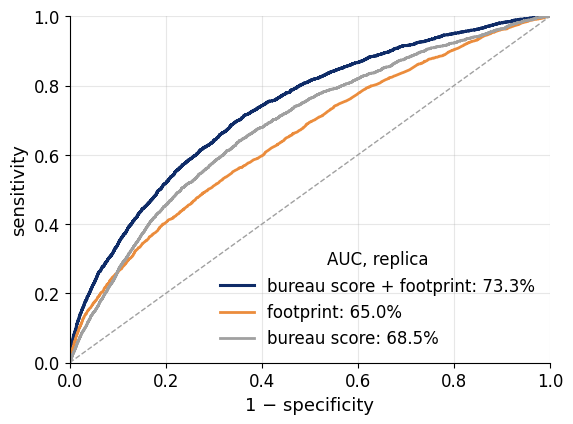

In [9]:
def roc_chart(curves, name, title):
    fig, ax = plt.subplots(figsize=(6.2, 4.5))
    for label, y, p, color, width in curves:
        fpr, tpr, _ = roc_curve(y, p)
        ax.plot(fpr, tpr, color=color, lw=width, label=f"{label}: {roc_auc_score(y, p):.1%}")
    ax.plot([0, 1], [0, 1], color=GREY, lw=1, ls="--")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("1 − specificity", fontsize=13)
    ax.set_ylabel("sensitivity", fontsize=13)
    ax.tick_params(labelsize=12)
    ax.legend(frameon=False, loc="lower right", title=title, fontsize=12, title_fontsize=12)
    fig.savefig(FIG / name)
    plt.show()


roc_chart([("bureau score + footprint", y_shop, p_shop["both"], NAVY, 2.2), ("footprint", y_shop, p_shop["footprint"], ORANGE, 2),
           ("bureau score", y_shop, p_shop["bureau score"], GREY, 2)], "roc_replica.png", "AUC, replica")

The replica's coefficients should be close to the ones we put in (column 3 of Table 5). With about 2,300 defaults their standard errors are around 0.1, so differences of that size are noise.

In [10]:
coefs_in = filled_coefs("coef with score", "default %")
coefs_in.index = [f"{v}: {c}" for v, c in coefs_in.index]
check = pd.DataFrame({"put in (Table 5, column 3)": coefs_in, "estimated on the replica": models_shop["both"].params}).dropna().round(2)
check

,"put in (Table 5, column 3)",estimated on the replica
channel: Affiliate,-0.54,-0.70
channel: Direct,-0.28,-0.28
channel: Organic,-0.15,-0.25
channel: Other,-0.48,-0.47
check-out time: Afternoon,0.08,0.11
check-out time: Morning,0.28,0.32
check-out time: Night,0.75,0.83
device: Desktop/Macintosh,-0.13,0.01
device: Do not track,-0.07,0.05
device: Mobile/Android,0.95,0.95


## 4. Home Credit: a footprint in public data

Home Credit is an international consumer lender. In 2018 it published 307,511 loan applications with their outcome for a Kaggle competition (`application_train.csv`, Home Credit Default Risk). `TARGET` is 1 when the client had payment difficulties, which is the default definition of the data set. We download the file once from a public copy on Hugging Face (166 MB, about half a minute); it is the same file as on Kaggle, where it needs a login and accepting the competition rules.

The data has three external scores, `EXT_SOURCE_1` to `EXT_SOURCE_3`, described only as "normalized score from external data source". We use `EXT_SOURCE_3` as the bureau score: it has the highest AUC of the three (section 5 compares them), and it is missing for one client in five, which gives us an "unscorable" group like the paper's.

As the footprint we take what the application itself records and what says nothing about income, job, debt or credit history. The list follows the paper's Table 1 by analogy; we did not search for variables that raise the AUC, and we left out fields that describe the client's job (employer phone, occupation), because the paper's footprint has nothing like them:

| Paper | Home Credit |
|---|---|
| check-out time (morning, afternoon, evening, night) | hour the application was started, with the paper's four time bands; day of the week |
| email host, name in email | whether an email address was given |
| device and operating system | whether a home phone and a work phone were given; how long ago the phone number was last changed |
| channel | who came along to apply (alone, family, spouse, others) |
| email error, lower case | contact address in a different city from the registered address; the optional housing questions left blank |

In [11]:
URL = "https://huggingface.co/datasets/Rohanerk/home-credit-default-risk/resolve/main/application_train.csv"


def download(url, path):
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path


path = download(URL, DATA / "application_train.csv")
raw = pd.read_csv(path)
print(f"file size {path.stat().st_size:,} bytes (Kaggle: 166,133,370)")
print(f"{len(raw):,} loans, {raw.TARGET.sum():,} defaults ({raw.TARGET.mean():.2%})")

file size 166,133,370 bytes (Kaggle: 166,133,370)
307,511 loans, 24,825 defaults (8.07%)


In [12]:
HOUSING = [c for c in raw.columns if c.endswith(("_AVG", "_MODE", "_MEDI"))]


def yes_no(s):
    return np.where(s == 1, "Yes", "No")


def footprint(raw):
    days = -raw.DAYS_LAST_PHONE_CHANGE.fillna(raw.DAYS_LAST_PHONE_CHANGE.median())
    return pd.DataFrame({
        "default": raw.TARGET,
        "time": pd.cut(raw.HOUR_APPR_PROCESS_START, [-1, 5, 11, 17, 23], labels=["Night", "Morning", "Afternoon", "Evening"]).astype(str),
        "weekday": raw.WEEKDAY_APPR_PROCESS_START.str.title(),
        "email given": yes_no(raw.FLAG_EMAIL),
        "home phone given": yes_no(raw.FLAG_PHONE),
        "work phone given": yes_no(raw.FLAG_WORK_PHONE),
        "phone changed": pd.cut(days, [-1, 30, 182, 365, 730, 10**5],
                                labels=["within a month", "1–6 months ago", "6–12 months ago", "1–2 years ago", "over 2 years ago"]).astype(str),
        "came with": raw.NAME_TYPE_SUITE.replace({"Children": "Family", "Group of people": "Others", "Other_A": "Others",
                                                  "Other_B": "Others"}).fillna("Not recorded"),
        "address in other city": yes_no(raw.REG_CITY_NOT_LIVE_CITY),
        "housing left blank": yes_no(raw[HOUSING].isna().all(axis=1).astype(int)),
        "score": 100 * raw.EXT_SOURCE_3,
    })


hc = footprint(raw)
HC_VARS = [c for c in hc if c not in ("default", "score")]
scorable, unscorable = hc[hc.score.notna()].copy(), hc[hc.score.isna()].drop(columns="score")
HC_BASE = {v: "No" if set(scorable[v]) == {"Yes", "No"} else scorable[v].value_counts().index[0] for v in HC_VARS}
print(f"with a score: {len(scorable):,} loans, default {scorable.default.mean():.2%}")
print(f"without a score: {len(unscorable):,} loans, default {unscorable.default.mean():.2%}")
HC_BASE

with a score: 246,546 loans, default 7.77%
without a score: 60,965 loans, default 9.31%


{'time': 'Afternoon',
 'weekday': 'Wednesday',
 'email given': 'No',
 'home phone given': 'No',
 'work phone given': 'No',
 'phone changed': 'over 2 years ago',
 'came with': 'Unaccompanied',
 'address in other city': 'No',
 'housing left blank': 'No'}

### Is the data what we think it is?

Before any model: the file has the 307,511 loans and the 8.07% default rate of the Kaggle competition. Clients without a score default more often, as in the paper (2.49% against 0.94% there). Next, as in the paper's Table 3, the default rate by category for the clients with a score. If the hour of the application carries information, we should see it here already.

In [13]:
def category_table(df):
    rows = []
    for var in HC_VARS:
        base = df.default[df[var] == HC_BASE[var]].mean()
        for cat, g in df.groupby(var):
            p = g.default.mean()
            se = np.sqrt(base * (1 - base) / (df[var] == HC_BASE[var]).sum() + p * (1 - p) / len(g))
            rows.append((var, cat, len(g), 100 * len(g) / len(df), 100 * p, "baseline" if cat == HC_BASE[var] else round((base - p) / se, 2)))
    return pd.DataFrame(rows, columns=["variable", "category", "loans", "share %", "default %", "t against baseline"]).round(2)


hc_rates = category_table(scorable)
hc_rates

,variable,category,loans,share %,default %,t against baseline
0,time,Afternoon,123808,50.22,7.56,baseline
1,time,Evening,11844,4.80,6.87,2.81
2,time,Morning,105429,42.76,8.04,-4.28
3,time,Night,5465,2.22,9.08,-3.83
4,weekday,Friday,40893,16.59,7.88,-0.41
5,weekday,Monday,40142,16.28,7.56,1.33
6,weekday,Saturday,27545,11.17,7.66,0.73
7,weekday,Sunday,12726,5.16,7.61,0.75
8,weekday,Thursday,40700,16.51,7.77,0.21
9,weekday,Tuesday,42094,17.07,7.93,-0.63


The hour of the application shows the same order as in the paper: night is the riskiest time and evening the safest. In the paper the night default rate is 2.3 times the evening rate; in Home Credit the gap is much smaller. Other variables also separate clients (a recently changed phone number, a contact address in another city, the housing questions left blank), but no single category comes close to the paper's email error, where the default rate is almost six times the baseline.

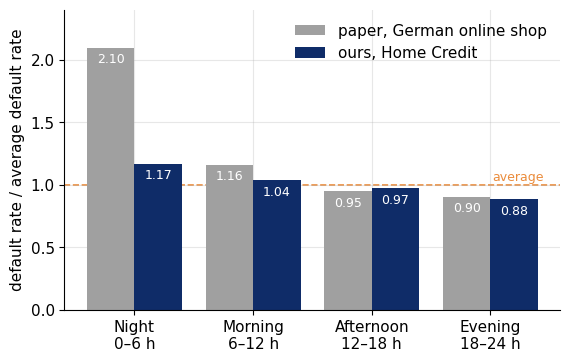

,paper,ours
Night,2.10,1.17
Morning,1.16,1.04
Afternoon,0.95,0.97
Evening,0.90,0.88


In [14]:
def relative_time(paper, ours):
    order = ["Night", "Morning", "Afternoon", "Evening"]
    p = paper.set_index("category").loc[order, "default %"] / PAPER_DEFAULT
    o = ours.groupby("time").default.mean().loc[order] / ours.default.mean()
    fig, ax = plt.subplots(figsize=(6.4, 3.9))
    x = np.arange(len(order))
    ax.axhline(1, color=ORANGE, lw=1.2, ls="--", zorder=1)
    ax.text(3.45, 1.03, "average", color=ORANGE, fontsize=9, ha="right")
    ax.bar(x - 0.2, p, 0.4, color=GREY, label="paper, German online shop", zorder=2)
    ax.bar(x + 0.2, o, 0.4, color=NAVY, label="ours, Home Credit", zorder=2)
    for i in range(len(order)):
        for dx, v, color in [(-0.2, p.iloc[i], "#555555"), (0.2, o.iloc[i], NAVY)]:
            ax.text(x[i] + dx, v - 0.04, f"{v:.2f}", ha="center", va="top", fontsize=9, color="white", zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(["Night\n0–6 h", "Morning\n6–12 h", "Afternoon\n12–18 h", "Evening\n18–24 h"])
    ax.set_ylabel("default rate / average default rate")
    ax.set_ylim(0, 2.4)
    ax.legend(frameon=False, loc="upper right")
    fig.savefig(FIG / "time_of_day.png")
    plt.show()
    return pd.DataFrame({"paper": p, "ours": o})


time_of_day = relative_time(PAPER[PAPER.variable == "check-out time"], scorable)
time_of_day.round(2)

## 5. Bureau score against footprint (Table 5 and Figure 4)

The paper's main result: the footprint alone has an AUC of 69.6%, the bureau score alone 68.3%, both together 73.6%. We fit the same three logit models on the Home Credit clients with a score.

In [15]:
y_hc, X_hc, models_hc, p_hc = three_models(scorable, HC_BASE)
hc_auc = auc_table(y_hc, p_hc)
hc_auc.insert(0, "paper", PAPER_AUC.loc[["bureau score", "footprint", "both"], "in sample"])
hc_tests = tests(y_hc, p_hc)
display(hc_auc.round(4))
hc_tests.round(4)

,paper,AUC,SE
bureau score,0.683,0.6794,0.0021
footprint,0.696,0.5831,0.0022
both,0.736,0.6913,0.0020


,difference,z,p-value
footprint minus bureau score,-0.0963,-33.4464,0.0
both minus bureau score,0.0119,16.5602,0.0
both minus footprint,0.1082,45.8626,0.0


In [16]:
coefficients = pd.DataFrame({"coef": models_hc["footprint"].params, "z": models_hc["footprint"].tvalues,
                             "coef with score": models_hc["both"].params, "z with score": models_hc["both"].tvalues}).round(2)
coefficients

,coef,z,coef with score,z with score
address in other city: Yes,0.39,15.81,0.24,9.56
came with: Family,-0.09,-3.90,-0.02,-1.08
came with: Not recorded,-0.55,-3.90,-0.60,-4.23
came with: Others,0.10,1.31,0.14,1.72
"came with: Spouse, partner",-0.03,-0.79,0.06,1.41
const,-2.80,-117.38,-1.27,-43.65
email given: Yes,0.05,1.46,-0.09,-2.70
home phone given: Yes,-0.23,-12.78,-0.21,-11.47
housing left blank: Yes,0.22,13.94,0.22,14.01
phone changed: 1–2 years ago,0.32,16.19,0.22,10.57


In Home Credit the footprint alone ranks clients clearly worse than the bureau score, so the first claim of the paper does not carry over. The second does: adding the footprint to the score raises the AUC, and the DeLong test says the gain is far from chance. Several footprint coefficients shrink by about a third when the score is added (in the paper they barely change), so here part of what the footprint says is already in the score.

The ROC curves on the same axes as the paper's Figure 4:

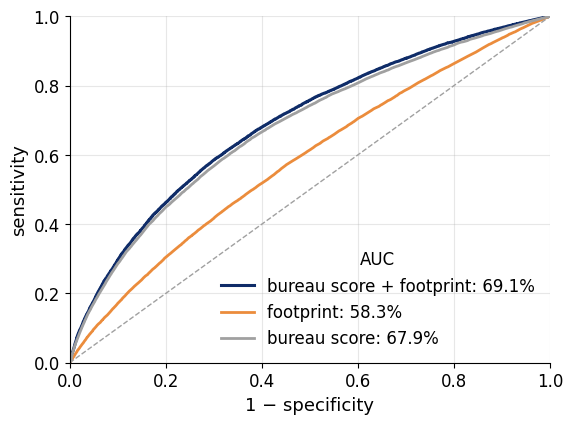

In [17]:
roc_chart([("bureau score + footprint", y_hc, p_hc["both"], NAVY, 2.2), ("footprint", y_hc, p_hc["footprint"], ORANGE, 2),
           ("bureau score", y_hc, p_hc["bureau score"], GREY, 2)], "roc.png", "AUC")

### Does it depend on which external score we call the bureau score?

We repeat the comparison with each of the three external scores, each time on the clients who have it. The footprint model is refitted on the same clients.

In [18]:
def against_score(col):
    df = hc.drop(columns="score").assign(score=100 * raw[col]).dropna(subset=["score"])
    y, _, _, p = three_models(df, HC_BASE)
    return {"loans": len(df), "default %": 100 * df.default.mean(), **{k: roc_auc_score(y, v) for k, v in p.items()}}


ext_scores = pd.DataFrame({col: against_score(col) for col in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]}).T
ext_scores.round(3)

,loans,default %,bureau score,footprint,both
EXT_SOURCE_1,134133.0,7.496,0.666,0.579,0.672
EXT_SOURCE_2,306851.0,8.073,0.656,0.587,0.665
EXT_SOURCE_3,246546.0,7.767,0.679,0.583,0.691


Whichever external score we take, the footprint alone is 7 to 10 points below it, and adds about half a point to a bit more than one point to it.

### A wider footprint

Is our footprint simply too poor? We add the fields we left out because they describe the job rather than the application: whether an employer phone was given, whether the occupation was left blank, the number of documents handed in, and a work address in another city.

In [19]:
wider = scorable.assign(**{
    "employer phone given": yes_no(raw.loc[scorable.index, "FLAG_EMP_PHONE"]),
    "occupation left blank": yes_no(raw.loc[scorable.index, "OCCUPATION_TYPE"].isna().astype(int)),
    "documents": raw.loc[scorable.index].filter(like="FLAG_DOCUMENT").sum(axis=1).clip(upper=2).astype(str),
    "work in other city": yes_no(raw.loc[scorable.index, "REG_CITY_NOT_WORK_CITY"])})
WIDER_BASE = {**HC_BASE, "employer phone given": "Yes", "occupation left blank": "No", "documents": "1", "work in other city": "No"}
_, _, _, p_wide = three_models(wider, WIDER_BASE)
wider_auc = pd.Series({k: roc_auc_score(y_hc, v) for k, v in p_wide.items()}, name="AUC, wider footprint")
wider_auc.round(4)

bureau score    0.6794
footprint       0.6082
both            0.6996
Name: AUC, wider footprint, dtype: float64

Even with these job-related fields the footprint stays far below the bureau score. We keep the narrower list for everything that follows.

## 6. Complements or substitutes? (Table 4 and Figure 5)

If the footprint only repeated what the bureau score knows, the two would be strongly related. The paper reports Cramér's V between the bureau score quintile and each footprint variable of 0.01 to 0.07 (0 means no association, 1 a perfect one), and a correlation of about 10% between the percentiles of the two scores (R² of 1.0%). In our replica they are unrelated by construction, so this test is only possible on Home Credit.

In [20]:
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / table.values.sum() / (min(table.shape) - 1))


quintile = pd.qcut(scorable.score, 5, labels=False)
cramer = pd.Series({v: cramers_v(quintile, scorable[v]) for v in HC_VARS}, name="Cramér's V with score quintile").round(3)
cramer

time                     0.024
weekday                  0.007
email given              0.051
home phone given         0.004
work phone given         0.061
phone changed            0.044
came with                0.023
address in other city    0.077
housing left blank       0.013
Name: Cramér's V with score quintile, dtype: float64

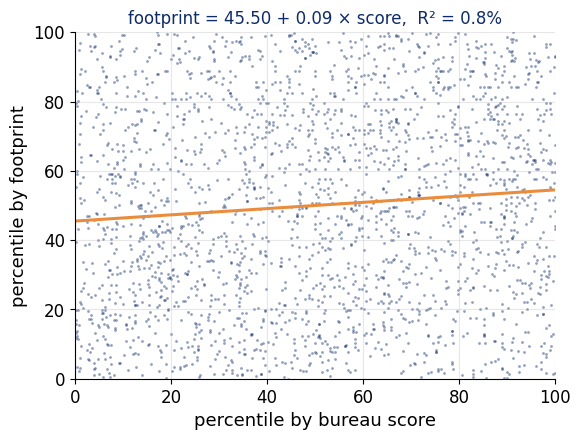

{'intercept': np.float64(45.49604482262368),
 'slope': np.float64(0.09008279420649218),
 'correlation': np.float64(0.09008325946547575),
 'R2': np.float64(0.008114993635924227),
 'points shown': 2404}

In [21]:
def percentile_chart(score, risk, name, seed):
    pct_score = 100 * rankdata(score) / len(score)
    pct_footprint = 100 * rankdata(-risk) / len(risk)
    slope, intercept = np.polyfit(pct_score, pct_footprint, 1)
    r = np.corrcoef(pct_score, pct_footprint)[0, 1]
    sample = np.random.default_rng(seed).random(len(score)) < 0.01
    fig, ax = plt.subplots(figsize=(6.2, 4.5))
    ax.scatter(pct_score[sample], pct_footprint[sample], s=4, color=NAVY, alpha=0.45, lw=0)
    xs = np.array([0, 100])
    ax.plot(xs, intercept + slope * xs, color=ORANGE, lw=2.2)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_xlabel("percentile by bureau score", fontsize=13)
    ax.set_ylabel("percentile by footprint", fontsize=13)
    ax.tick_params(labelsize=12)
    ax.set_title(f"footprint = {intercept:.2f} + {slope:.2f} × score,  R² = {r ** 2:.1%}", fontsize=12, color=NAVY)
    fig.savefig(FIG / name)
    plt.show()
    return {"intercept": intercept, "slope": slope, "correlation": r, "R2": r ** 2, "points shown": int(sample.sum())}


complement = percentile_chart(scorable.score.values, p_hc["footprint"], "percentiles.png", SEED)
complement

As in the paper, the relation is very weak: Cramér's V between 0.004 and 0.077 (paper 0.01 to 0.07), and a correlation of the two percentiles of 9% (R² of 0.8%, paper 1.0%). Most clients with a good score have an average footprint, and the other way round. This is why adding the footprint to the score helps even though the footprint alone is weak.

## 7. Clients without a bureau score (Tables 6 and 7, Figure 6)

For the 6% of the shop's customers who have no bureau score, the paper finds that the footprint works at least as well as for the others: AUC 72.2% against 69.6% in sample, 68.3% against 68.8% out of sample. We fit the footprint model on the Home Credit clients without `EXT_SOURCE_3`.

In [22]:
y_u = unscorable.default.values
X_u = design(unscorable, HC_BASE)
model_u = fit(y_u, X_u)
p_u = model_u.predict(X_u)
unscorable_auc = pd.DataFrame({
    "loans": [len(scorable), len(unscorable)],
    "defaults": [int(scorable.default.sum()), int(unscorable.default.sum())],
    "default %": [100 * scorable.default.mean(), 100 * unscorable.default.mean()],
    "footprint AUC": [roc_auc_score(y_hc, p_hc["footprint"]), roc_auc_score(y_u, p_u)],
    "SE": [auc_se(y_hc, p_hc["footprint"]), auc_se(y_u, p_u)],
    "paper AUC": [0.696, 0.722]}, index=["with a score", "without a score"])
unscorable_auc.round(4)

,loans,defaults,default %,footprint AUC,SE,paper AUC
with a score,246546,19148,7.7665,0.5831,0.0022,0.696
without a score,60965,5677,9.3119,0.5967,0.0040,0.722


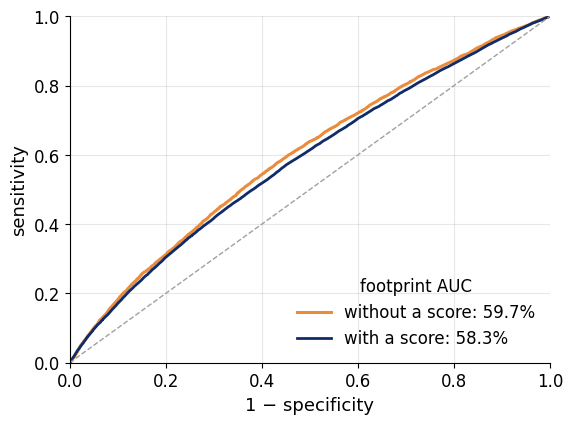

In [23]:
roc_chart([("without a score", y_u, p_u, ORANGE, 2.2), ("with a score", y_hc, p_hc["footprint"], NAVY, 2)], "roc_unscorable.png", "footprint AUC")

As in the paper, the footprint works at least as well for clients without a score (59.7% against 58.3%), and these clients default more often (9.3% against 7.8%). The level is far below the paper's, but the conclusion carries over. Out of sample (next section) the order stays the same.

## 8. Could this be overfit?

Every AUC so far is in sample: the model is judged on the same customers it was fitted on, which flatters it, and more so the fewer defaults there are per coefficient. The paper answers with N×2-fold cross-validation (its Table 8): split the sample at random into two halves, fit on one half and predict the other, then the other way round, compute the AUC on all the out-of-sample predictions, and repeat 100 times. In the paper the AUCs fall by less than one point for customers with a score (2.8 points in a model with month and region fixed effects, which we do not rebuild), and by 3.9 points (72.2% to 68.3%) for the 15,591 customers without one, who have only about 390 defaults.

We run the same procedure on the replica, where we know there is nothing to find beyond the paper's own coefficients, and on Home Credit. The replica tells us how much of the paper's drop is what a sample of that size does by chance.

In [24]:
def cross_validated_auc(y, X, repeats, seed):
    rng = np.random.default_rng(seed)
    y, X = np.asarray(y), np.asarray(X, float)
    aucs = []
    for _ in range(repeats):
        half = rng.random(len(y)) < 0.5
        p = np.zeros(len(y))
        for train in (half, ~half):
            p[~train] = sm.Logit(y[train], X[train]).fit(disp=0, method="newton", maxiter=100).predict(X[~train])
        aucs.append(roc_auc_score(y, p))
    return np.mean(aucs)


def in_and_out(y, X, p):
    return {"in sample": roc_auc_score(y, p), "out of sample": cross_validated_auc(y, X, REPEATS, SEED + 100), "defaults": int(np.sum(y))}


cv = {}
for name in ["bureau score", "footprint", "both"]:
    cv[("replica", name)] = in_and_out(y_shop, X_shop[name], p_shop[name])
    cv[("Home Credit", name)] = in_and_out(y_hc, X_hc[name], p_hc[name])
cv[("replica", "footprint, unscorable")] = in_and_out(shop_unscorable.default.values, X_shop_u, p_shop_u)
cv[("Home Credit", "footprint, unscorable")] = in_and_out(y_u, X_u, p_u)
cv = pd.DataFrame(cv).T
cv["drop, points"] = 100 * (cv["in sample"] - cv["out of sample"])
paper_defaults = [round(PAPER_DEFAULT / 100 * 254808)] * 3 + [round(PAPER_DEFAULT_UNSCORABLE / 100 * 15591)]
paper_cv = PAPER_AUC.assign(defaults=paper_defaults).assign(**{"drop, points": 100 * (PAPER_AUC["in sample"] - PAPER_AUC["out of sample"])})
paper_cv.index = pd.MultiIndex.from_product([["paper"], paper_cv.index])
cv = pd.concat([paper_cv, cv]).astype(float)
cv.round(4)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


in sample  out of sample  defaults  drop, points
paper       bureau score              0.6830         0.6800    2395.0        0.3000
            footprint                 0.6960         0.6880    2395.0        0.8000
            both                      0.7360         0.7280    2395.0        0.8000
            footprint, unscorable     0.7220         0.6830     388.0        3.9000
replica     bureau score              0.6853         0.6847    2341.0        0.0522
Home Credit bureau score              0.6794         0.6793   19148.0        0.0058
replica     footprint                 0.6497         0.6427    2341.0        0.6981
Home Credit footprint                 0.5831         0.5813   19148.0        0.1796
replica     both                      0.7331         0.7292    2341.0        0.3913
Home Credit both                      0.6913         0.6906   19148.0        0.0701
replica     footprint, unscorable     0.7268         0.6970     374.0        2.9711
Home Credit footprint, unscorable     0.5967         0.5914    5677.0        0.5306

The paper's numbers of defaults are 0.94% of 254,808 and 2.49% of 15,591. The chart shows the drop from in-sample to out-of-sample AUC for the footprint model in each sample.

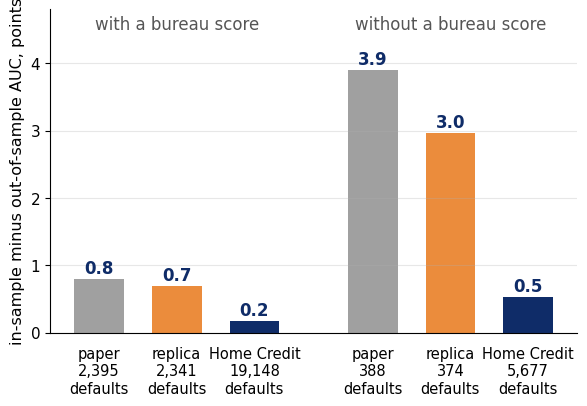

In [25]:
def overfit_chart(cv):
    sources = [("paper", GREY), ("replica", ORANGE), ("Home Credit", NAVY)]
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    for g, (model, title) in enumerate([("footprint", "with a bureau score"), ("footprint, unscorable", "without a bureau score")]):
        for k, (source, color) in enumerate(sources):
            x = 4.4 * g + 1.25 * k
            d, n = cv.loc[(source, model), "drop, points"], cv.loc[(source, model), "defaults"]
            ax.bar(x, d, color=color, width=0.8)
            ax.text(x, d + 0.08, f"{d:.1f}", ha="center", fontsize=12, color=NAVY, fontweight="bold")
            ax.text(x, -0.2, f"{source}\n{int(n):,}\ndefaults", ha="center", va="top", fontsize=10.5)
        ax.text(4.4 * g + 1.25, 4.5, title, ha="center", fontsize=12, color="#555555")
    ax.set_xticks([])
    ax.tick_params(labelsize=11)
    ax.set_ylabel("in-sample minus out-of-sample AUC, points", fontsize=11.5)
    ax.set_ylim(0, 4.8)
    ax.grid(axis="x", alpha=0)
    fig.savefig(FIG / "out_of_sample.png")
    plt.show()


overfit_chart(cv)

With a bureau score the out-of-sample AUCs are below the in-sample ones by less than one point everywhere, as in the paper. For customers without a score the replica, which contains nothing beyond the paper's own coefficients, loses 3.0 points, close to the paper's 3.9: most of the paper's drop is what fitting two dozen coefficients on fewer than 400 defaults does by chance, not a sign that the footprint is fitted to noise. Home Credit has many more defaults, so its drops are a fraction of a point.

## 9. The upgrade: the paper's claims on a new dataset

We put the paper's five claims next to what Home Credit shows. "Holds" means the direction and the conclusion carry over, not that the numbers are the same: a lender of cash and revolving loans is a different setting from an online furniture shop.

In [26]:
fp_hc, sc_hc, both_hc = hc_auc.loc["footprint", "AUC"], hc_auc.loc["bureau score", "AUC"], hc_auc.loc["both", "AUC"]
cv_hc_u = cv.loc[("Home Credit", "footprint, unscorable"), "out of sample"]
cv_hc_s = cv.loc[("Home Credit", "footprint"), "out of sample"]
verdict = pd.DataFrame([
    ("the footprint alone is as good as the bureau score", "69.6% vs 68.3%", f"{fp_hc:.1%} vs {sc_hc:.1%}", fp_hc >= sc_hc - 0.005),
    ("the two are almost unrelated", "correlation about 10%", f"correlation {complement['correlation']:.0%}", complement["correlation"] < 0.3),
    ("together they beat either one", "+5.3 points over the score", f"+{100 * (both_hc - sc_hc):.1f} points", hc_tests.loc["both minus bureau score", "p-value"] < 0.01),
    ("the footprint works as well without a bureau score", "68.3% vs 68.8% out of sample", f"{cv_hc_u:.1%} vs {cv_hc_s:.1%} out of sample", cv_hc_u >= cv_hc_s - 0.01),
    ("out of sample the AUCs barely fall", "below 1 point, no fixed effects", f"{cv.loc[('Home Credit', 'footprint'), 'drop, points']:.1f} points", cv.loc[("Home Credit", "footprint"), "drop, points"] < 1),
], columns=["claim", "paper", "Home Credit", "holds"]).set_index("claim")
verdict["holds"] = np.where(verdict.holds, "yes", "no")
verdict

,paper,Home Credit,holds
claim,,,
the footprint alone is as good as the bureau score,69.6% vs 68.3%,58.3% vs 67.9%,no
the two are almost unrelated,correlation about 10%,correlation 9%,yes
together they beat either one,+5.3 points over the score,+1.2 points,yes
the footprint works as well without a bureau score,68.3% vs 68.8% out of sample,59.1% vs 58.1% out of sample,yes
out of sample the AUCs barely fall,"below 1 point, no fixed effects",0.2 points,yes


## 10. Summary

The main numbers of the paper next to ours. All tables of this notebook are also saved to `results.json`; the README and the slides take their numbers from that file.

In [27]:
summary = pd.DataFrame([
    ["AUC, bureau score", "68.3%", f"{replica_auc.loc['bureau score', 'AUC']:.1%}", f"{sc_hc:.1%}"],
    ["AUC, footprint", "69.6%", f"{replica_auc.loc['footprint', 'AUC']:.1%}", f"{fp_hc:.1%}"],
    ["AUC, both", "73.6%", f"{replica_auc.loc['both', 'AUC']:.1%}", f"{both_hc:.1%}"],
    ["AUC, footprint without a score", "72.2%", f"{replica_auc.loc['footprint, unscorable', 'AUC']:.1%}", f"{unscorable_auc.loc['without a score', 'footprint AUC']:.1%}"],
    ["correlation of the two scores", "about 10%", "0 by construction", f"{complement['correlation']:.0%}"],
    ["drop out of sample, footprint without a score", "3.9 points",
     f"{cv.loc[('replica', 'footprint, unscorable'), 'drop, points']:.1f} points", f"{cv.loc[('Home Credit', 'footprint, unscorable'), 'drop, points']:.1f} points"],
], columns=["result", "paper", "replica", "Home Credit"]).set_index("result")

cv_flat = cv.copy()
cv_flat.index = [f"{a}, {b}" for a, b in cv.index]
tables = {"single": single, "rates": rates.set_index(rates.variable + ": " + rates.category).drop(columns=["variable", "category"]),
          "replica_auc": replica_auc, "replica_tests": replica_tests, "hc_rates": hc_rates.set_index(hc_rates.variable + ": " + hc_rates.category).drop(columns=["variable", "category"]),
          "time_of_day": time_of_day, "hc_auc": hc_auc, "hc_tests": hc_tests, "coefficients": coefficients, "ext_scores": ext_scores,
          "wider": wider_auc.to_frame(), "cramer": cramer.to_frame("V"), "unscorable": unscorable_auc, "cv": cv_flat, "verdict": verdict}
extra = {**{f"complement {k}": float(v) for k, v in complement.items()},
         "loans": len(raw), "defaults": int(raw.TARGET.sum()), "default %": 100 * raw.TARGET.mean(),
         "scorable loans": len(scorable), "unscorable loans": len(unscorable), "file bytes": path.stat().st_size,
         "replica customers": len(shop), "replica defaults": int(shop.default.sum()),
         "replica unscorable customers": len(shop_unscorable), "replica unscorable defaults": int(shop_unscorable.default.sum()),
         "footprint variables": len(HC_VARS), "repeats": REPEATS}
with open(ROOT / "results.json", "w") as f:
    json.dump({"tables": {name: json.loads(t.astype(str).to_json()) for name, t in tables.items()}, "extra": extra,
               "summary": summary.astype(str).to_dict()}, f, indent=1)
summary

,paper,replica,Home Credit
result,,,
"AUC, bureau score",68.3%,68.5%,67.9%
"AUC, footprint",69.6%,65.0%,58.3%
"AUC, both",73.6%,73.3%,69.1%
"AUC, footprint without a score",72.2%,72.7%,59.7%
correlation of the two scores,about 10%,0 by construction,9%
"drop out of sample, footprint without a score",3.9 points,3.0 points,0.5 points
